# §0. Exploratory Data Analysis

In [1]:
! python --version

Python 3.13.11


## §0.1 Data Description: Triagegeist Dataset

In this section, we provide a description of the [dataset](https://www.kaggle.com/competitions/triagegeist/data) used for analysis, including the types of variables, their distributions, and any notable characteristics.

Key characteristics of the dataset include:
- Fully synthetic data with no real patient information.
- Covers a simulated 24-month period across multiple fictional hospital sites.
- Includes structured intake data, free-text chief complaint narratives, and disposition outcomes.
- Designed to reflect realistic statistical distributions and clinical relationships observed in emergency medicine literature.


More realistic data can be obtained from MIMIC-IV ED (Emergency Department) published by the MIT Laboratory for Computational Physiology. Refer to the official documentation for access and usage guidelines: [MIMIC-IV ED Documentation](https://physionet.org/content/mimic-iv-ed/2.2/)

In [2]:
import os
import glob
from pathlib import Path
from IPython.display import HTML, display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 14
plt.rcParams["xtick.labelsize"] = 12
plt.rcParams["ytick.labelsize"] = 12
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["figure.dpi"] = 100

sns.set_theme(style="whitegrid")
sns.set_context("notebook")
sns.set_palette("pastel")

In [3]:
DATAPATH = Path("../data")

def list_data_files(datapath=DATAPATH):
    for file in datapath.glob("*"):
        if file.is_file():
            print(file.name)

def read_data(filename, datapath=DATAPATH):
    file_path = datapath / filename
    if file_path.is_file():
        return pd.read_csv(file_path)
    else:
        raise FileNotFoundError(f"{file_path} does not exist.")

def display_html(filepath:Path):
    display(HTML(filepath.read_text()))
    
train = read_data("train.csv")
test = read_data("test.csv")

display_html(DATAPATH/"files.html")
display_html(DATAPATH/"schemma.html")
display_html(DATAPATH/"chief_complaints.html")

File,Format,Description
train.csv,CSV,Training set. Contains patient intake features and triage acuity label.
test.csv,CSV,Test set. Contains patient intake features without acuity label.
chief_complaints.csv,CSV,Free-text chief complaint narratives linked to records via patient_id.
sample_submission.csv,CSV,A valid submission file in the required format.


Column,Type,Description
patient_id,string,Unique patient identifier. Links to chief_complaints.csv.
arrival_mode,categorical,"Mode of arrival: ambulance, walk-in, transfer, police."
arrival_hour,integer,Hour of arrival (0-23).
arrival_day,categorical,Day of week: Monday through Sunday.
age,integer,Patient age in years.
sex,categorical,"M, F, Other."
systolic_bp,float,Systolic blood pressure (mmHg) at triage.
diastolic_bp,float,Diastolic blood pressure (mmHg) at triage.
heart_rate,float,Heart rate (bpm) at triage.
respiratory_rate,float,Respiratory rate (breaths/min) at triage.


Column,Type,Description
patient_id,string,Links to train.csv and test.csv.
chief_complaint_raw,string,Raw free-text chief complaint as entered by triage nurse.


In [4]:
def info_data(data: pd.DataFrame):
    print("Shape:", data.shape)
    print("\nInfo:")
    print(data.info())

In [5]:
info_data(train)

Shape: (80000, 40)

Info:
<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 40 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                80000 non-null  str    
 1   site_id                   80000 non-null  str    
 2   triage_nurse_id           80000 non-null  str    
 3   arrival_mode              80000 non-null  str    
 4   arrival_hour              80000 non-null  int64  
 5   arrival_day               80000 non-null  str    
 6   arrival_month             80000 non-null  int64  
 7   arrival_season            80000 non-null  str    
 8   shift                     80000 non-null  str    
 9   age                       80000 non-null  int64  
 10  age_group                 80000 non-null  str    
 11  sex                       80000 non-null  str    
 12  language                  80000 non-null  str    
 13  insurance_type            80000 non-null  str 

In [6]:
info_data(test)

Shape: (20000, 37)

Info:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 37 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                20000 non-null  str    
 1   site_id                   20000 non-null  str    
 2   triage_nurse_id           20000 non-null  str    
 3   arrival_mode              20000 non-null  str    
 4   arrival_hour              20000 non-null  int64  
 5   arrival_day               20000 non-null  str    
 6   arrival_month             20000 non-null  int64  
 7   arrival_season            20000 non-null  str    
 8   shift                     20000 non-null  str    
 9   age                       20000 non-null  int64  
 10  age_group                 20000 non-null  str    
 11  sex                       20000 non-null  str    
 12  language                  20000 non-null  str    
 13  insurance_type            20000 non-null  str 

## §0.2 Missing Values in Vital Signs
Author's notes on missing values in data:

>"Missing values are present in ´systolic_bp´, ´diastolic_bp´, ´heart_rate´, ´respiratory_rate´, ´temperature_c´, ´spo2´, and ´pain_score´. Missingness is not random and reflects realistic triage conditions in which certain vitals are not obtained for lower-acuity patients."

Some imputation strategy should be considered for dealing with these missing values.

In [7]:
# Missing Data Analysis
missing_colums = train.columns[train.isnull().any()]

def print_missing_values(df):
    missing_colums = df.columns[df.isnull().any()]
    for col in missing_colums:
        print(f"{col}: {df[col].isnull().sum()} ({df[col].isnull().mean():.2%}) missing values")

print("Missing values in train dataset:")
print("--")
print_missing_values(train)
print("\n")
print("Missing values in test dataset:")
print("--")
print_missing_values(test)


Missing values in train dataset:
--
systolic_bp: 4146 (5.18%) missing values
diastolic_bp: 4146 (5.18%) missing values
mean_arterial_pressure: 4146 (5.18%) missing values
pulse_pressure: 4146 (5.18%) missing values
respiratory_rate: 3067 (3.83%) missing values
temperature_c: 574 (0.72%) missing values
shock_index: 4146 (5.18%) missing values


Missing values in test dataset:
--
systolic_bp: 962 (4.81%) missing values
diastolic_bp: 962 (4.81%) missing values
mean_arterial_pressure: 962 (4.81%) missing values
pulse_pressure: 962 (4.81%) missing values
respiratory_rate: 752 (3.76%) missing values
temperature_c: 106 (0.53%) missing values
shock_index: 962 (4.81%) missing values


In [8]:
LABEL = 'triage_acuity'
dropped_columns = set(train.columns) - set(test.columns)
if LABEL in dropped_columns:
    dropped_columns.remove(LABEL)
print("Dropped Columns:", dropped_columns)

train = train.drop(columns=dropped_columns)

Dropped Columns: {'ed_los_hours', 'disposition'}


In [39]:
train.columns

Index(['patient_id', 'site_id', 'triage_nurse_id', 'arrival_mode',
       'arrival_hour', 'arrival_day', 'arrival_month', 'arrival_season',
       'shift', 'age', 'age_group', 'sex', 'language', 'insurance_type',
       'transport_origin', 'pain_location', 'mental_status_triage',
       'chief_complaint_system', 'num_prior_ed_visits_12m',
       'num_prior_admissions_12m', 'num_active_medications',
       'num_comorbidities', 'systolic_bp', 'diastolic_bp',
       'mean_arterial_pressure', 'pulse_pressure', 'heart_rate',
       'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score',
       'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score',
       'triage_acuity'],
      dtype='str')

In [40]:
# Let's validate some aspects of the train dataset

# Any duplicate patient IDs
duplicate_patient_ids = train['patient_id'].duplicated().sum()
print("Duplicate Patient IDs:", duplicate_patient_ids)

# Any missing patient IDs
missing_patient_ids = train['patient_id'].isna().sum()
print("Missing Patient IDs:", missing_patient_ids)

# Any duplicate rows
duplicate_rows = train.duplicated().sum()
print("Duplicate Rows:", duplicate_rows)

Duplicate Patient IDs: 0
Missing Patient IDs: 0
Duplicate Rows: 0


# §0.3 Summary of statistical distributions

In [41]:
num_columns = train.select_dtypes(include=['number']).columns.tolist()
print("Number of numerical columns:", len(num_columns))
print("Numerical columns:", num_columns)

Number of numerical columns: 23
Numerical columns: ['arrival_hour', 'arrival_month', 'age', 'num_prior_ed_visits_12m', 'num_prior_admissions_12m', 'num_active_medications', 'num_comorbidities', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total', 'pain_score', 'weight_kg', 'height_cm', 'bmi', 'shock_index', 'news2_score', 'triage_acuity']


In [42]:
id_columns = ['patient_id', 'site_id', 'triage_nurse_id']
cat_columns = train.select_dtypes(include=['str']).columns
cat_columns = set(cat_columns) - set(id_columns)
cat_columns = list(cat_columns)
print("Number of categorical columns:", len(cat_columns))
print("Categorical columns:", cat_columns)

Number of categorical columns: 12
Categorical columns: ['sex', 'arrival_day', 'shift', 'arrival_mode', 'age_group', 'language', 'mental_status_triage', 'insurance_type', 'arrival_season', 'pain_location', 'chief_complaint_system', 'transport_origin']


In [12]:

esi_colors = {1: 'red', 2: 'orange', 3: 'yellow', 4: 'green', 5: 'blue'}


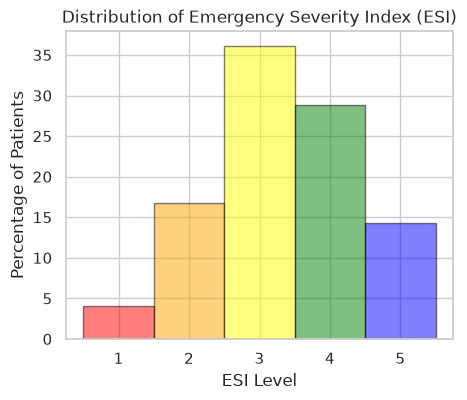

Level 1 is the highest priority, while level 5 is the lowest priority


In [11]:
# Plot distribution of target variable (Emergency Severity Index - ESI) in relative terms

fig, ax = plt.subplots(figsize=(5, 4))
hp = sns.histplot(data=train, x=LABEL, ax=ax, stat="percent", discrete=True)
for p in hp.patches:
    p.set_facecolor(esi_colors[int(p.get_x()+1)])
    p.set_edgecolor('black')
    p.set_alpha(0.5)
plt.title("Distribution of Emergency Severity Index (ESI)")
plt.xlabel("ESI Level")
plt.ylabel("Percentage of Patients")
plt.show()
print("Level 1 is the highest priority, while level 5 is the lowest priority")

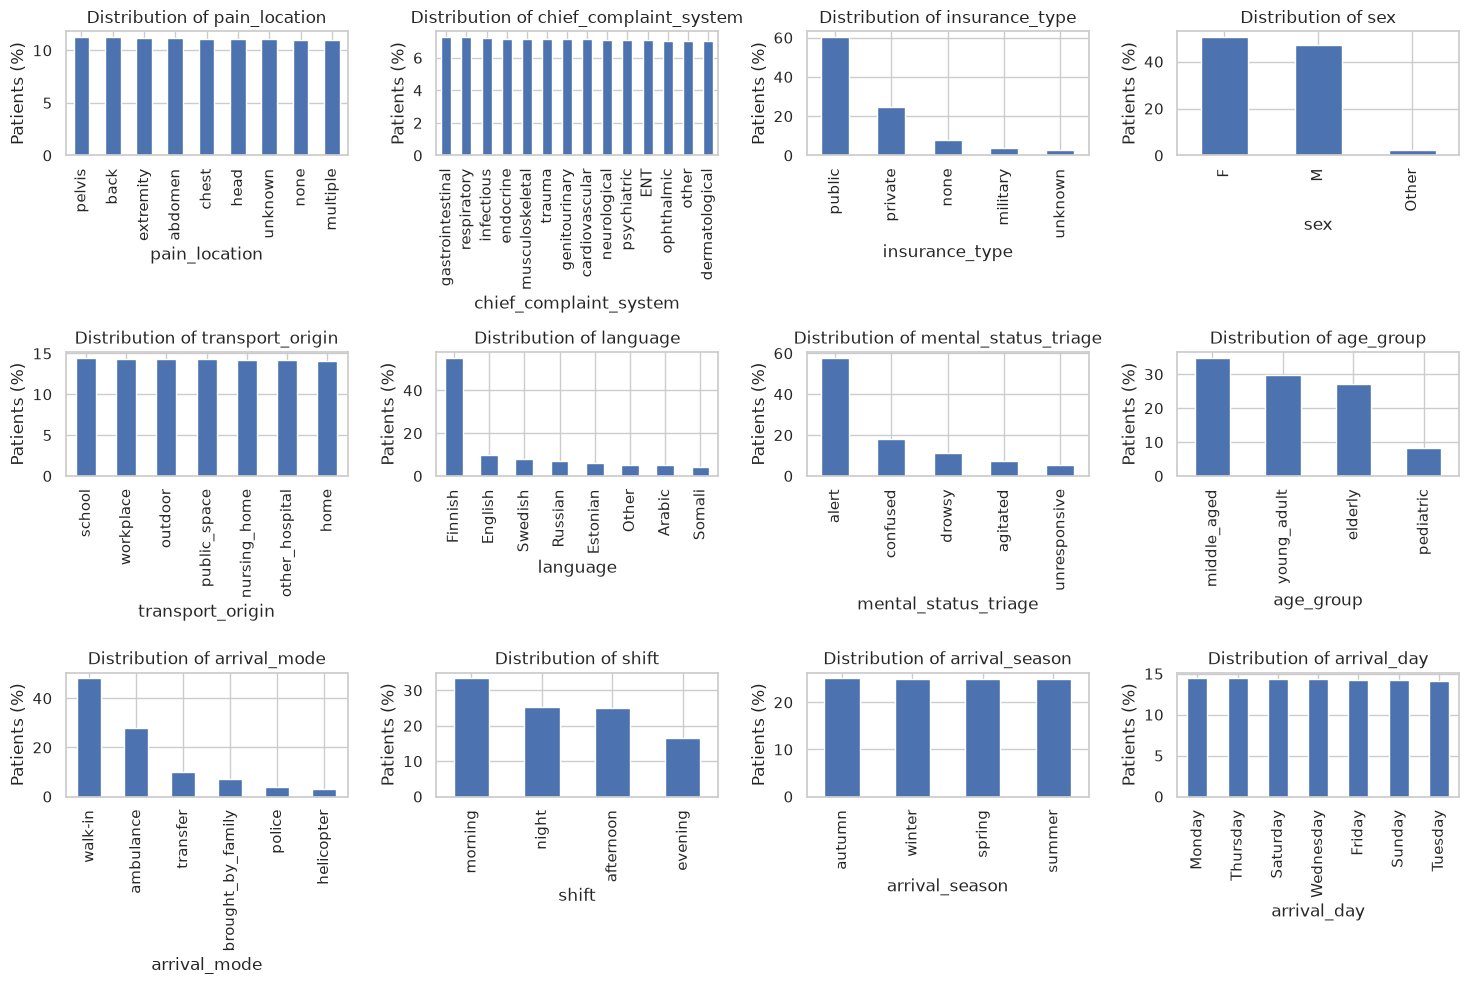

In [88]:
# Plot distributions of categorical variables in relative terms

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for col in cat_columns:
    values = train[col].value_counts(normalize=True) * 100
    ax = axes[cat_columns.index(col) // 4, cat_columns.index(col) % 4]
    values.plot(kind='bar', ax=ax, ylabel='Patients (%)')
    ax.set_title(f'Distribution of {col}')
    
plt.tight_layout()


In [46]:
# plot pairplot plot for numerical variables
time_variables = ['arrival_hour', 'arrival_month']
demographic_variables = ['age', 'weight_kg', 'height_cm']
concurrency_variables = ['num_prior_ed_visits_12m', 'num_prior_admissions_12m']
vital_signs_variables = ['systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2']
other_variables = ['num_active_medications', 'num_comorbidities',  'gcs_total', 'pain_score', 'bmi', 'shock_index', 'news2_score']


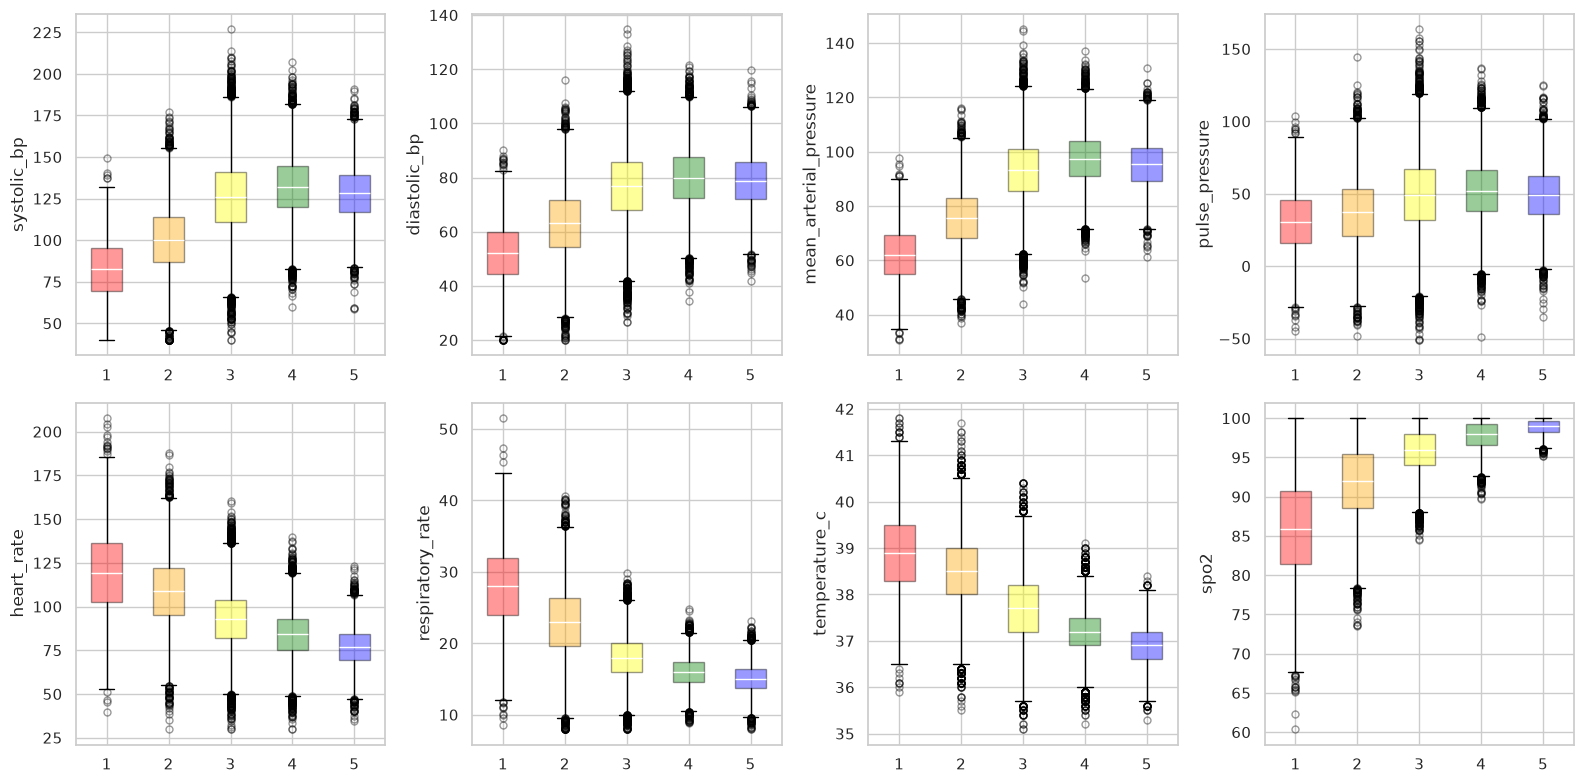

In [49]:
# vital signs by ESI level
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
esi_colors = {1: 'red', 2: 'orange', 3: 'yellow', 4: 'green', 5: 'blue'}

for ax, sign in zip(axes, vital_signs_variables):   
    groups = [train.loc[train[LABEL] == i, sign].dropna()
            for i in range(1, 6)]
    bp = ax.boxplot(groups, positions=range(5), patch_artist=True, medianprops=dict(color='white'), boxprops=dict(alpha=0.4, linewidth=1), flierprops=dict(marker='o', alpha=0.4, markersize=5, color='gray'))
    for patch, color in zip(bp['boxes'], esi_colors.values()):
        patch.set_facecolor(color)
        
    ax.set_ylabel(sign)
    ax.set_xticklabels(esi_colors.keys())

plt.tight_layout()
plt.show()

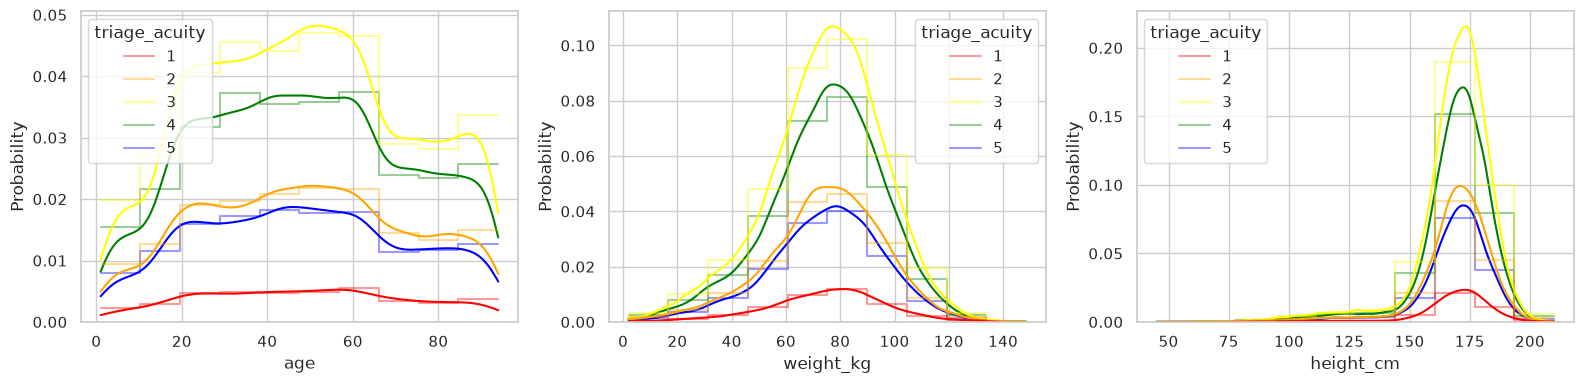

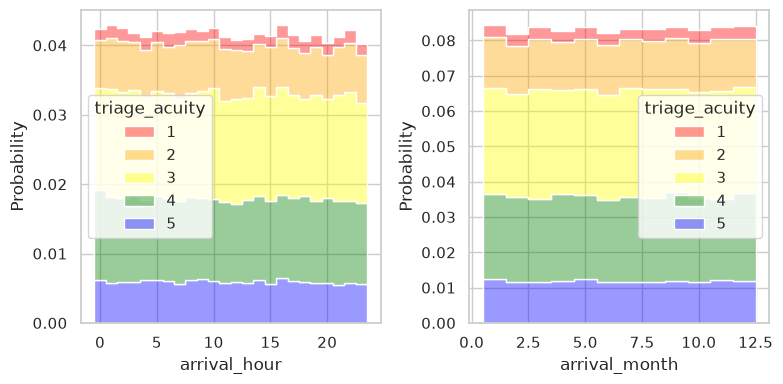

In [52]:
# Plot data distribution

esi_colors = {1: 'red', 2: 'orange', 3: 'yellow', 4: 'green', 5: 'blue'}

# Demographics
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, v in enumerate(demographic_variables):
    sns.histplot(data=train, x=v, hue=LABEL,ax=ax[i], kde=True, bins=10, stat='probability', element='step', multiple='layer', palette=esi_colors, alpha=0.4, fill=False)
    
plt.tight_layout()
plt.show()

# time-related variables
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for i, v in enumerate(time_variables):
    sns.histplot(data=train, x=v, hue=LABEL, ax=ax[i], stat='probability', element='step', multiple='stack', palette=esi_colors, alpha=0.4, fill=True, discrete=True)
plt.tight_layout()
plt.show()



In [63]:
train[["age", "age_group"]].groupby("age_group").agg(min_age=("age", "min"), max_age=("age", "max")).sort_values("min_age")

,min_age,max_age
age_group,,
pediatric,1,15
young_adult,16,39
middle_aged,40,64
elderly,65,94


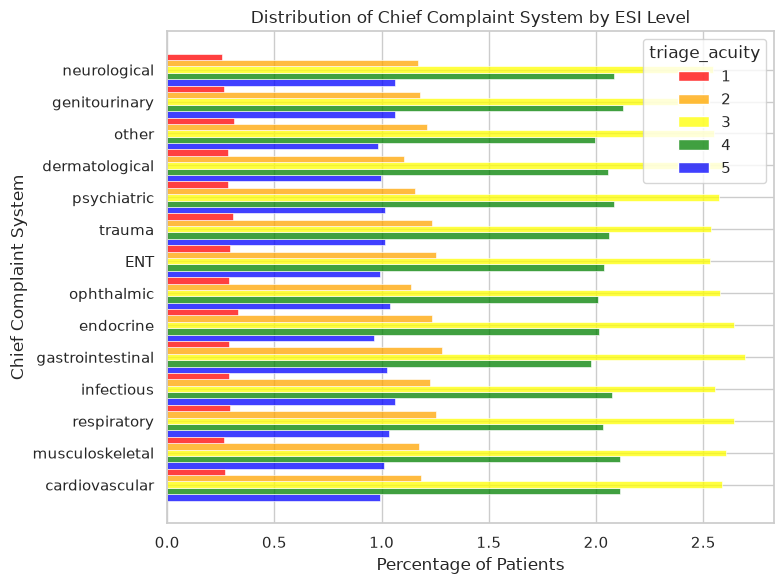

In [79]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(data=train, y="chief_complaint_system", hue=LABEL, ax=ax, stat="percent", discrete=True, palette=esi_colors, multiple="dodge")
plt.title("Distribution of Chief Complaint System by ESI Level")
plt.ylabel("Chief Complaint System")
plt.xlabel("Percentage of Patients")
plt.tight_layout()
plt.show()

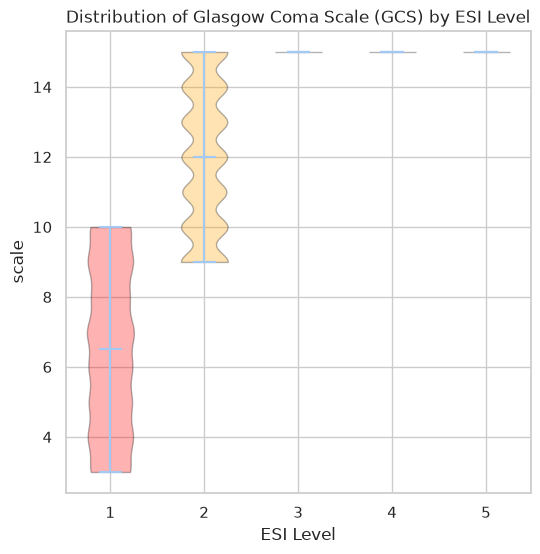

In [ ]:
groups = [train.loc[train[LABEL] == i, "gcs_total"].dropna()
            for i in range(1, 6)]

fig, ax = plt.subplots(figsize=(6, 6))
bp = ax.violinplot(groups, positions=range(5), showmedians=True)
for patch, color in zip(bp['bodies'], esi_colors.values()):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')    
ax.set_ylabel("scale")
ax.set_xticks(range(5))
ax.set_xticklabels(esi_colors.keys())
ax.set_xlabel("ESI Level")
ax.set_title("Distribution of Glasgow Coma Scale (GCS) by ESI Level")
plt.show()

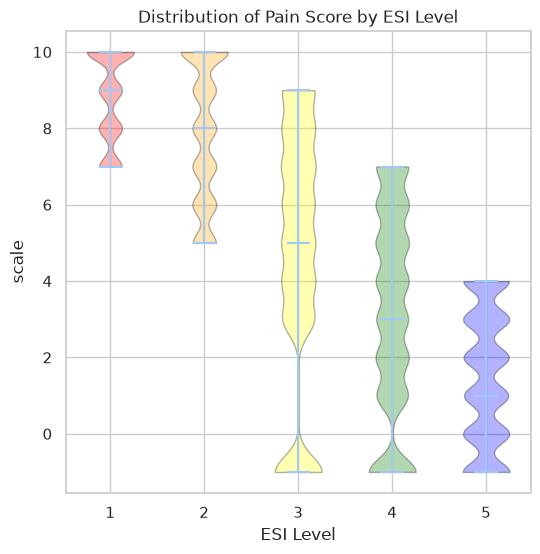

In [27]:
groups = [train.loc[train[LABEL] == i, "pain_score"].dropna()
            for i in range(1, 6)]

fig, ax = plt.subplots(figsize=(6, 6))
bp = ax.violinplot(groups, positions=range(5), showmedians=True)
for patch, color in zip(bp['bodies'], esi_colors.values()):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')    
ax.set_ylabel("scale")
ax.set_xticks(range(5))
ax.set_xticklabels(esi_colors.keys())
ax.set_xlabel("ESI Level")
ax.set_title("Distribution of Pain Score by ESI Level")
plt.show()

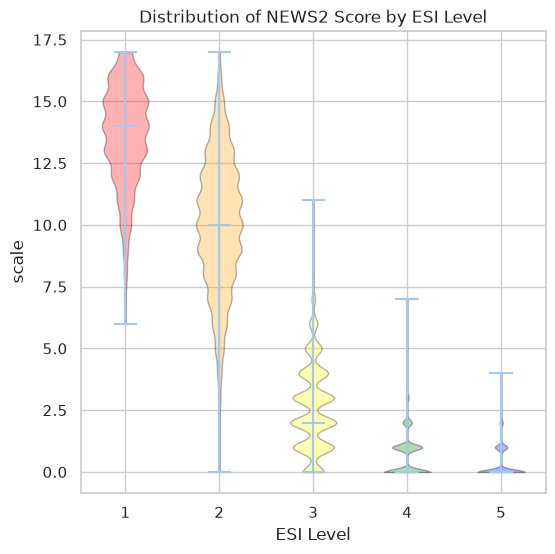

In [28]:
groups = [train.loc[train[LABEL] == i, "news2_score"].dropna()
            for i in range(1, 6)]

fig, ax = plt.subplots(figsize=(6, 6))
bp = ax.violinplot(groups, positions=range(5), showmedians=True)
for patch, color in zip(bp['bodies'], esi_colors.values()):
    patch.set_facecolor(color)
    patch.set_edgecolor('black')    
ax.set_ylabel("scale")
ax.set_xticks(range(5))
ax.set_xticklabels(esi_colors.keys())
ax.set_xlabel("ESI Level")
ax.set_title("Distribution of NEWS2 Score by ESI Level")
plt.show()